# NovaShop.cz: Exploratory Analysis & Anomaly Check
Python complements the SQL work: a visual check of daily orders and a rolling z-score anomaly test (A-04), which is awkward in SQLite.

**Prerequisite:** Part A done (the `fct_` and `dim_` tables exist in `data/retail.db`).

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect('../data/retail.db')
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con)

Matplotlib is building the font cache; this may take a moment.


,name
0,dim_channel
1,dim_customer
2,dim_date
3,dim_product
4,fct_daily_marketing
5,fct_order_items
6,raw_ad_spend
7,raw_customers
8,raw_email_campaigns
9,raw_email_events


## 1. First look at the raw orders

In [2]:
orders = pd.read_sql('SELECT * FROM raw_orders', con)
print(orders.shape)
print(orders['status'].value_counts())
print(orders['platform'].value_counts(normalize=True).round(3))

(33325, 11)
status
completed     27405
returned       2510
cancelled      1411
Completed       607
completed       586
COMPLETED       561
returned         56
Returned         51
RETURNED         49
Cancelled        33
CANCELLED        28
cancelled        28
Name: count, dtype: int64
platform
web    0.611
app    0.389
Name: proportion, dtype: float64


## 2. Daily orders by platform
Orders are used instead of revenue because daily revenue is noisy (a few expensive items swing it).

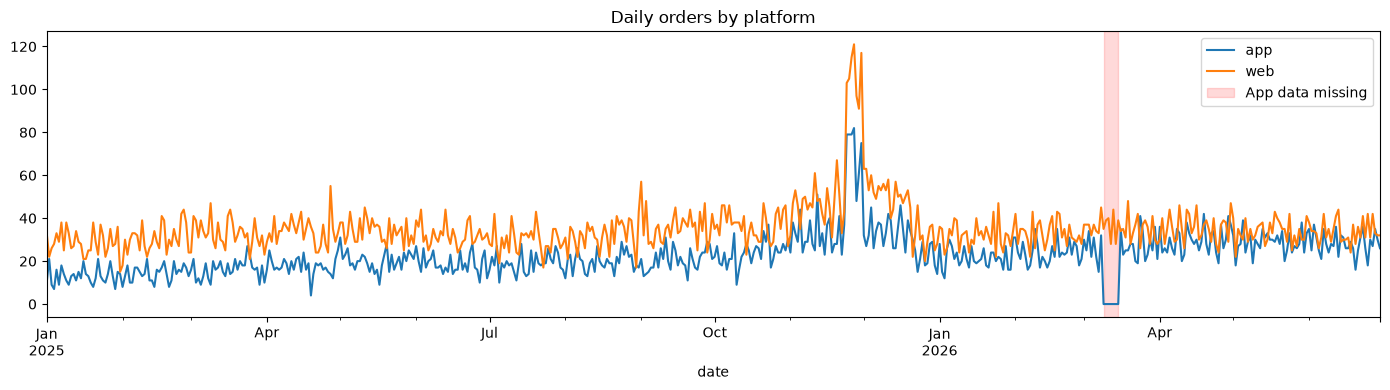

In [3]:
daily = pd.read_sql("""
    SELECT d.date, p.platform,
           COUNT(DISTINCT f.order_id) AS orders
    FROM dim_date d
    CROSS JOIN (SELECT 'web' AS platform UNION ALL SELECT 'app') p
    LEFT JOIN fct_order_items f
           ON f.order_date = d.date AND f.platform = p.platform AND f.status <> 'cancelled'
    GROUP BY d.date, p.platform
""", con, parse_dates=['date'])

wide = daily.pivot(index='date', columns='platform', values='orders')
ax = wide.plot(figsize=(14, 4), title='Daily orders by platform')
ax.axvspan(pd.Timestamp('2026-03-09'), pd.Timestamp('2026-03-15'), color='red', alpha=0.15, label='App data missing')
ax.legend()
plt.tight_layout()
plt.savefig('../powerbi/screenshots/daily_orders_by_platform.png', dpi=120)
plt.show()

## 3. Rolling z-score anomaly detection (A-04)
z-score = how many standard deviations a day is from the previous 28 days. |z| > 3 is flagged.

In [4]:
roll_mean = wide.rolling(28, min_periods=14).mean().shift(1)   # shift(1): today not in its own baseline
roll_std  = wide.rolling(28, min_periods=14).std().shift(1)
z = (wide - roll_mean) / roll_std

flags = z[(z.abs() > 3).any(axis=1)].round(1)
flags

platform,app,web
date,,
2025-03-24,3.2,-0.2
2025-04-19,-3.5,0.5
2025-04-27,-0.8,3.9
2025-05-01,3.3,0.6
2025-09-01,0.3,3.8
2025-11-12,3.7,0.9
2025-11-24,6.6,6.6
2025-11-25,4.0,4.1
2025-11-26,3.1,3.7


## 4. Findings
- The z-score check (|z| > 3) confirms the SQL findings: Black Friday week is the largest spike (z = +6.6), and app orders on 9-10 Mar 2026 are strongly negative (z = -4.4) while web stays normal.
- Days 11-15 Mar are no longer flagged: once the missing days enter the 28-day window they drag the baseline down. This is a known weakness of rolling baselines, so the SQL same-weekday check plus the completeness view are the better production alert.
- Python adds value for quick visual checks and statistics that are awkward in SQLite (standard deviation), while SQL stays the source of the reporting layer.